# Etapa 2 — Exploración y análisis de las fuentes de datos del sandbox de OTC Consulting

**Reto de Business Intelligence — Socio formador OTC Consulting (OT Consulting, S.A. de C.V.)**
**Alumno — José Fernando Munguía Zertuche, A01199357**

En esta etapa se realiza la navegación y exploración detallada de las fuentes de datos entregadas por el socio formador, archivo por archivo y columna por columna, como base para los requerimientos de análisis del reto. Las fuentes son los archivos Excel que exporta el sandbox HR Management de OTC, una PWA hospedada en Firebase que el área de Recursos Humanos usa para administrar colaboradores, asignaciones, clientes, activos y habilidades.

**Objeto de estudio.** El hecho a analizar es la asignación de consultores a proyectos de clientes y su costo, porque OTC vende las horas y el conocimiento de su gente. La problemática de fondo es que la herramienta registra la operación pero no la convierte en análisis, pues su pantalla de resumen solo muestra cuatro conteos y dos gráficas, sin utilización, sin costo de la gente sin proyecto y sin alertas, y los datos fuente traen vacíos e inconsistencias que hoy impiden calcular esos indicadores con confianza.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)

BASE = Path('../data/excel')
ARCHIVOS = {
    'colaboradores':  ('Catalogo_Colaboradores.xlsx', 0),
    'asignaciones':   ('Asignaciones_Colaboradores.xlsx', 0),
    'clientes':       ('Catalogo_Clientes.xlsx', 'Clientes'),
    'proyectos':      ('Catalogo_Clientes.xlsx', 'Proyectos'),
    'activos':        ('Catalogo_Activos.xlsx', 'Activos'),
    'resguardos':     ('Catalogo_Activos.xlsx', 'Resguardos'),
    'matriz':         ('Matriz_Habilidades.xlsx', 0),
    'habilidades':    ('Catalogo_Habilidades.xlsx', 0),
    'departamentos':  ('Catalogo_Departamentos.xlsx', 0),
    'roles':          ('Catalogo_Roles.xlsx', 0),
}
datos = {}
for nombre, (archivo, hoja) in ARCHIVOS.items():
    datos[nombre] = pd.read_excel(BASE / archivo, sheet_name=hoja)
    print(f'{nombre:15s} <- {archivo:35s} {datos[nombre].shape[0]:5d} filas x {datos[nombre].shape[1]:2d} columnas')

col  = datos['colaboradores']
asig = datos['asignaciones']
cli  = datos['clientes']
pro  = datos['proyectos']
act  = datos['activos']
res  = datos['resguardos']
mat  = datos['matriz']
hab  = datos['habilidades']
dep  = datos['departamentos']
rol  = datos['roles']

colaboradores   <- Catalogo_Colaboradores.xlsx           107 filas x 39 columnas
asignaciones    <- Asignaciones_Colaboradores.xlsx        31 filas x 13 columnas
clientes        <- Catalogo_Clientes.xlsx                  8 filas x 13 columnas
proyectos       <- Catalogo_Clientes.xlsx                 12 filas x 11 columnas
activos         <- Catalogo_Activos.xlsx                 123 filas x 16 columnas
resguardos      <- Catalogo_Activos.xlsx                  91 filas x 12 columnas


matriz          <- Matriz_Habilidades.xlsx              1539 filas x 10 columnas
habilidades     <- Catalogo_Habilidades.xlsx              71 filas x  6 columnas
departamentos   <- Catalogo_Departamentos.xlsx             6 filas x  7 columnas
roles           <- Catalogo_Roles.xlsx                    55 filas x  7 columnas


## 1. Metadata de las fuentes

Cada archivo corresponde a un módulo del sandbox y se describe con palabras propias a partir de su contenido real.

- **Catalogo_Colaboradores** guarda el expediente operativo de cada colaborador con su puesto, departamento, estatus, fechas de ingreso y baja, esquema de nómina, los componentes de su sueldo y las banderas de documentos de su expediente. Su llave es la columna uid y su folio visible es id.
- **Asignaciones_Colaboradores** es la tabla de hechos del estudio, pues une a cada colaborador con el cliente y el proyecto donde trabaja, el rol que desempeña, el tipo de asignación y sus fechas de inicio y fin.
- **Catalogo_Clientes** trae el catálogo de clientes con su industria y contacto, y en su hoja Proyectos el detalle de los proyectos de cada cliente con responsable, gerente de OTC y estatus.
- **Catalogo_Activos** trae el inventario de equipo con marca, serie, costo y fechas de compra y garantía, y en su hoja Resguardos el historial de qué colaborador tiene o tuvo cada equipo.
- **Matriz_Habilidades** registra en formato largo el nivel de cada colaborador en cada habilidad, con la tecnología y el tipo de habilidad.
- **Catalogo_Habilidades** es el catálogo de habilidades con su código, descripción, tecnología y tipo duro o blando.
- **Catalogo_Departamentos** es el catálogo de áreas con su objetivo, responsable y centro de costos.
- **Catalogo_Roles** es el catálogo de puestos con su nivel y departamento, y se incluye como fuente complementaria porque el sandbox también lo exporta. El módulo de Usuarios se excluye a propósito de este repositorio porque contiene credenciales de acceso, y los identificadores directos de los colaboradores como CURP, RFC, NSS, domicilio y datos bancarios también se excluyen del catálogo publicado por protección de datos.

In [2]:
# Inventario general de las fuentes
resumen = []
for nombre, df in datos.items():
    resumen.append({
        'tabla': nombre,
        'filas': len(df),
        'columnas': len(df.columns),
        'celdas_vacias_%': round(df.replace('', np.nan).isna().mean().mean() * 100, 1),
        'filas_duplicadas': int(df.duplicated().sum()),
    })
pd.DataFrame(resumen)

,tabla,filas,columnas,celdas_vacias_%,filas_duplicadas
0,colaboradores,107,39,10.6,0
1,asignaciones,31,13,6.0,0
2,clientes,8,13,27.9,0
3,proyectos,12,11,37.1,0
4,activos,123,16,21.2,0
5,resguardos,91,12,15.7,0
6,matriz,1539,10,0.3,0
7,habilidades,71,6,0.0,0
8,departamentos,6,7,28.6,0
9,roles,55,7,0.5,0


## 2. Perfilado columna por columna

Se recorre cada archivo y cada columna registrando su tipo, sus valores vacíos, sus valores distintos y un ejemplo, para conocer los datos al cien por ciento antes de proponer cualquier análisis.

In [3]:
def perfilar(nombre, df):
    print(f'===== {nombre} ({len(df)} filas) =====')
    for c in df.columns:
        s = df[c].replace('', np.nan)
        ej = s.dropna().iloc[0] if s.notna().any() else '—'
        print(f'{c:26s} tipo={str(df[c].dtype):8s} vacios={s.isna().sum():4d} ({s.isna().mean()*100:5.1f}%)  distintos={s.nunique():4d}  ejemplo={ej}')
    print()

for nombre, df in datos.items():
    perfilar(nombre, df)

===== colaboradores (107 filas) =====
id                         tipo=str      vacios=   0 (  0.0%)  distintos= 107  ejemplo=OTC003
nombre                     tipo=str      vacios=   0 (  0.0%)  distintos= 107  ejemplo=ABRAHAM PEREZ GIL
puesto                     tipo=str      vacios=   0 (  0.0%)  distintos=  24  ejemplo=PENDIENTE
depto                      tipo=str      vacios=  95 ( 88.8%)  distintos=   2  ejemplo=Operaciones y Soporte
estatus                    tipo=str      vacios=   0 (  0.0%)  distintos=   2  ejemplo=Activo
genero                     tipo=str      vacios=   0 (  0.0%)  distintos=   2  ejemplo=Masculino
ciudad                     tipo=str      vacios=   0 (  0.0%)  distintos=  25  ejemplo=Monterrey
email                      tipo=str      vacios=   0 (  0.0%)  distintos=   1  ejemplo=colaborador@otconsulting.com.mx
telefono                   tipo=int64    vacios=   0 (  0.0%)  distintos=   1  ejemplo=999999999
fechainc                   tipo=str      vacios=   1 

In [4]:
# Tipos de datos y memoria por tabla
for nombre, df in datos.items():
    print(f'--- {nombre} ---')
    print(df.dtypes.to_string())
    print()

--- colaboradores ---
id                            str
nombre                        str
puesto                        str
depto                         str
estatus                       str
genero                        str
ciudad                        str
email                         str
telefono                    int64
fechainc                      str
fechabaja                     str
fechanac                      str
nomina                        str
sueldo_imss               float64
sueldo_asimilados         float64
sueldo_complementos       float64
sueldo_neto_total         float64
comision_nomina           float64
impuestos_imss            float64
sueldo_total_integrado    float64
segvida                       str
sgmm                          str
med_condiciones               str
doc_acta                      str
doc_banco                     str
doc_compdom                   str
doc_contrato                  str
doc_csf                       str
doc_curp                  

## 3. Errores, datos faltantes e inconsistencias

Los hallazgos se buscan de forma sistemática sobre los datos y no a simple vista, revisando vacíos críticos, valores placeholder, duplicados, catálogos sin normalizar y relaciones rotas entre tablas.

In [5]:
hallazgos = []
def H(severidad, tabla_campo, hallazgo, impacto):
    hallazgos.append({'severidad': severidad, 'tabla_campo': tabla_campo, 'hallazgo': hallazgo, 'impacto': impacto})

# Colaboradores
dep_vacio = col.depto.replace('', np.nan).isna().mean()
H('ALTA', 'colaboradores.depto', f'{dep_vacio*100:.1f}% de los colaboradores no tiene departamento',
  'No se puede analizar plantilla ni costo por área')
pend = (col.puesto == 'PENDIENTE').mean()
H('ALTA', 'colaboradores.puesto', f'{pend*100:.1f}% tiene puesto PENDIENTE, un valor placeholder del catálogo',
  'El análisis por puesto pierde casi a la mitad de la plantilla')
H('CRÍTICA', 'colaboradores.email y telefono',
  f'Solo {col.email.nunique()} correo distinto y {col.telefono.nunique()} teléfono distinto en {len(col)} registros',
  'Son datos anonimizados en origen y no sirven como llave ni para contacto')
bajas = col[col.estatus == 'Baja']
sin_fb = bajas.fechabaja.replace('', np.nan).isna().sum()
H('ALTA', 'colaboradores.fechabaja', f'{sin_fb} de {len(bajas)} bajas no tienen fecha de baja',
  'No se puede calcular la rotación por periodo ni la antigüedad real al salir')
act_con_fb = col[(col.estatus == 'Activo') & col.fechabaja.replace('', np.nan).notna()]
H('MEDIA', 'colaboradores.fechabaja', f'{len(act_con_fb)} colaborador activo sí tiene fecha de baja',
  'Contradicción entre estatus y fechas que contamina cualquier corte por periodo')
docs = [c for c in col.columns if c.startswith('doc_')]
comp = (col[docs] == 'SI').mean().mean()
H('MEDIA', 'colaboradores.doc_', f'Cumplimiento documental promedio de {comp*100:.1f}% y ningún colaborador con el expediente completo',
  'El semáforo de expediente no puede usarse como meta')
H('MEDIA', 'colaboradores.doc_contrato', 'La columna guarda el tipo de contrato y no un sí o no como las demás banderas',
  'Mezcla dos significados en la familia de columnas de documentos')
sueldo0 = col[(col.estatus == 'Activo') & (col.sueldo_total_integrado.fillna(0) == 0)]
H('MEDIA', 'colaboradores.sueldo_total_integrado', f'{len(sueldo0)} colaboradores activos con sueldo integrado en cero',
  'Subestima la nómina y el costo por experto')

# Asignaciones y proyectos
H('ALTA', 'asignaciones.fin', f'{asig.fin.replace("", np.nan).isna().sum()} de {len(asig)} asignaciones no tienen fecha de fin',
  'No se puede saber quién termina pronto su asignación')
H('ALTA', 'asignaciones.inicio', f'{(asig.inicio == "1990-01-01").sum()} asignaciones usan la fecha centinela 1990-01-01',
  'Las duraciones calculadas salen de décadas si se usan directo')
H('ALTA', 'asignaciones.rol', f'{(asig.rol == "PENDIENTE").sum()} de {len(asig)} asignaciones con rol PENDIENTE',
  'No se puede validar que el rol asignado coincida con el puesto')
H('MEDIA', 'asignaciones.estatus', f'Las {len(asig)} asignaciones están En Curso y ninguna está cerrada',
  'No hay historial de asignaciones terminadas para medir duración real')
sin_asig = sorted(set(pro.cliente) - set(asig.cliente))
H('MEDIA', 'clientes contra asignaciones', f'{len(sin_asig)} clientes tienen proyectos y ninguna asignación registrada',
  'La operación de esos clientes es invisible en la tabla de hechos')

# Matriz y habilidades
huerf = mat[mat.colaborador.replace('', np.nan).isna()]
H('ALTA', 'matriz.uid_colaborador', f'{huerf.uid_colaborador.nunique()} documentos de matriz apuntan a colaboradores que no existen con {len(huerf)} pares',
  'Basura relacional que infla los conteos de habilidades')
mat_baja = mat[mat.estatus_colaborador == 'Baja'].uid_colaborador.nunique()
H('MEDIA', 'matriz contra colaboradores', f'{mat_baja} colaboradores dados de baja siguen con habilidades en la matriz',
  'La oferta de habilidades disponibles se sobreestima')
dup_hab = hab.descripcion.duplicated().sum()
H('MEDIA', 'habilidades.descripcion', f'{dup_hab} descripciones repetidas con códigos distintos entre Oracle eBS y Fusion Cloud',
  'Los conteos por habilidad se parten entre dos códigos equivalentes')

# Activos y resguardos
H('ALTA', 'activos.costo y fcompra', f'{(act.costo.fillna(0) == 0).sum()} de {len(act)} activos sin costo y sin fecha de compra',
  'El valor del inventario queda subestimado y no hay base de depreciación')
H('ALTA', 'activos.fgarantia', f'Ningún activo tiene fecha de garantía de {len(act)}',
  'No se puede alertar sobre garantías por vencer')
nf = act[act.notas.fillna('').str.contains('NO FUNCIONA') & (act.estatus == 'Activo')]
H('ALTA', 'activos.notas y estatus', f'{len(nf)} equipos marcados como que no funcionan siguen con estatus Activo',
  'Se puede seguir asignando equipo inservible')
abiertos_baja = res[(res.estatus_colaborador == 'Baja') & res.f_fin.replace('', np.nan).isna()]
H('ALTA', 'resguardos.f_fin', f'{len(abiertos_baja)} resguardos abiertos pertenecen a colaboradores dados de baja',
  'Riesgo de pérdida de equipo al no recuperarse en la salida')
H('MEDIA', 'activos.marca', f'{act.marca.nunique()} variantes escritas de marca para 5 marcas reales',
  'Los reportes por marca salen mal agregados sin normalizar')

# Departamentos y roles
H('MEDIA', 'departamentos.responsable y centroCostos', 'Ningún departamento tiene responsable ni centro de costos',
  'El catálogo de áreas no sirve para imputar costos ni responsables')
sin_uso = set(rol.nombre) - set(col.puesto)
H('BAJA', 'roles contra colaboradores', f'{len(sin_uso)} de {len(rol)} puestos del catálogo no los ocupa nadie',
  'Catálogo con puestos sin depurar que ensucia los selectores')

pd.DataFrame(hallazgos)

,severidad,tabla_campo,hallazgo,impacto
0,ALTA,colaboradores.depto,88.8% de los colaboradores no tiene departamento,No se puede analizar plantilla ni costo por área
1,ALTA,colaboradores.puesto,"44.9% tiene puesto PENDIENTE, un valor placeho...",El análisis por puesto pierde casi a la mitad ...
2,CRÍTICA,colaboradores.email y telefono,Solo 1 correo distinto y 1 teléfono distinto e...,Son datos anonimizados en origen y no sirven c...
3,ALTA,colaboradores.fechabaja,18 de 32 bajas no tienen fecha de baja,No se puede calcular la rotación por periodo n...
4,MEDIA,colaboradores.fechabaja,1 colaborador activo sí tiene fecha de baja,Contradicción entre estatus y fechas que conta...
5,MEDIA,colaboradores.doc_,Cumplimiento documental promedio de 45.5% y ni...,El semáforo de expediente no puede usarse como...
6,MEDIA,colaboradores.doc_contrato,La columna guarda el tipo de contrato y no un ...,Mezcla dos significados en la familia de colum...
7,MEDIA,colaboradores.sueldo_total_integrado,5 colaboradores activos con sueldo integrado e...,Subestima la nómina y el costo por experto
8,ALTA,asignaciones.fin,24 de 31 asignaciones no tienen fecha de fin,No se puede saber quién termina pronto su asig...
9,ALTA,asignaciones.inicio,21 asignaciones usan la fecha centinela 1990-0...,Las duraciones calculadas salen de décadas si ...


In [6]:
# Detalle de valores placeholder y constantes
print('Fechas centinela 1990-01-01 en asignaciones:', (asig.inicio == '1990-01-01').sum())
print('Fechas centinela 1990-01-01 en resguardos:  ', (res.f_ini == '1990-01-01').sum())
print('Correos distintos en colaboradores:       ', col.email.nunique())
print('Teléfonos distintos en colaboradores:     ', col.telefono.nunique())
print('Estatus de asignación:                    ', asig.estatus.value_counts().to_dict())
print('Marcas tal como están escritas:           ', sorted(act.marca.dropna().unique()))
print('Nivel de habilidad:                       ', mat.nivel.value_counts().to_dict())

Fechas centinela 1990-01-01 en asignaciones: 21
Fechas centinela 1990-01-01 en resguardos:   35
Correos distintos en colaboradores:        1
Teléfonos distintos en colaboradores:      1
Estatus de asignación:                     {'En Curso': 31}
Marcas tal como están escritas:            ['ACER', 'ASUS', 'Acer', 'DELL', 'DELL ', 'Dell', 'Dell ', 'HP', 'HP ', 'LENOVO', 'LENOVO ', 'Lenovo']
Nivel de habilidad:                        {'Básico': 687, 'Intermedio': 369, 'Experto': 249, 'Avanzado': 234}


## 4. Integridad referencial entre fuentes

Se verifica que cada llave foránea exista en su tabla padre, porque de estas relaciones dependen todos los cruces del análisis.

In [7]:
def integridad(hijos, padres, llave_hijo, llave_padre, nombre):
    ref = hijos[llave_hijo].replace('', np.nan).dropna()
    huerfanas = (~ref.isin(set(padres[llave_padre]))).sum()
    print(f'{nombre:55s} referencias={len(ref):5d}  huérfanas={huerfanas:3d}  integridad={(1 - huerfanas / max(len(ref),1)) * 100:.1f}%')
    return huerfanas

integridad(asig, col, 'uid_colaborador', 'uid', 'asignaciones -> colaboradores')
integridad(mat, col, 'uid_colaborador', 'uid', 'matriz -> colaboradores')
integridad(mat, hab, 'codigo_habilidad', 'codigo', 'matriz -> catálogo de habilidades')
integridad(res, col, 'uid_colaborador', 'uid', 'resguardos -> colaboradores')
integridad(res, act, 'codigo_activo', 'codigo', 'resguardos -> activos')
integridad(pro, cli, 'codigo_cliente', 'codigo', 'proyectos -> clientes')
print('Puestos de colaboradores fuera del catálogo de roles:', len(set(col.puesto) - set(rol.nombre)))
print('Departamentos capturados fuera del catálogo:        ', len(set(col.depto.replace('', np.nan).dropna()) - set(dep.nombre.str.strip())))

asignaciones -> colaboradores                           referencias=   31  huérfanas=  0  integridad=100.0%
matriz -> colaboradores                                 referencias= 1539  huérfanas= 10  integridad=99.4%
matriz -> catálogo de habilidades                       referencias= 1539  huérfanas=  0  integridad=100.0%
resguardos -> colaboradores                             referencias=   91  huérfanas=  0  integridad=100.0%
resguardos -> activos                                   referencias=   91  huérfanas=  0  integridad=100.0%
proyectos -> clientes                                   referencias=   12  huérfanas=  0  integridad=100.0%
Puestos de colaboradores fuera del catálogo de roles: 0
Departamentos capturados fuera del catálogo:         0


## 5. Reglas de negocio para el tratamiento de los datos

Las reglas que se acuerdan para estandarizar el manejo de los datos son las siguientes. Un colaborador activo debe tener una sola asignación principal vigente y puede apoyar en asignaciones secundarias solo si se registra su porcentaje de dedicación. Un gerente de proyecto puede estar en varios proyectos a la vez. Toda baja debe llevar su fecha de baja y al registrarse deben cerrarse sus asignaciones y sus resguardos de equipo. Ninguna asignación es válida sin fecha de inicio real y la fecha centinela 1990-01-01 se trata como dato faltante y nunca como fecha. El puesto y el departamento son obligatorios y se toman de los catálogos por su código y no por texto libre, y el valor PENDIENTE solo se permite como estado temporal con fecha de corrección. El sueldo total integrado debe ser igual a la suma de sus componentes y se valida en cada corte. Cada habilidad de la matriz debe llevar su fecha de evaluación y su evaluador para poder medir su evolución. Las marcas de activos se normalizan en mayúsculas sin espacios y un equipo que no funciona cambia a estatus de baja técnica y cierra su resguardo. El costo por hora de un experto se deriva de su sueldo total integrado mensual entre 160 horas como supuesto explícito de costeo mientras el socio no entregue las horas reales facturables.

In [8]:
# Evaluación de reglas de negocio medibles con las fuentes actuales
def regla(nombre, serie_mask, universo):
    inc = int(serie_mask.sum())
    print(f'{nombre:70s} incumplen {inc:3d} de {universo}')
    return inc

regla('Baja implica fecha de baja capturada', bajas.fechabaja.replace('', np.nan).isna(), len(bajas))
regla('Activo implica fecha de baja vacía', (col.estatus == 'Activo') & col.fechabaja.replace('', np.nan).notna(), (col.estatus == 'Activo').sum())
regla('Sueldo neto total igual a la suma de sus componentes',
      (col.sueldo_neto_total - (col.sueldo_imss + col.sueldo_asimilados + col.sueldo_complementos)).abs() > 0.01, len(col))
regla('Equipo que no funciona no puede estar Activo',
      act.notas.fillna('').str.contains('NO FUNCIONA') & (act.estatus == 'Activo'), len(act))
regla('Resguardo de una baja debe estar cerrado',
      (res.estatus_colaborador == 'Baja') & res.f_fin.replace('', np.nan).isna(), len(res))
regla('Asignación con fecha de inicio real y no centinela', asig.inicio == '1990-01-01', len(asig))
regla('Colaborador con departamento capturado', col.depto.replace('', np.nan).isna(), len(col))
regla('Colaborador con puesto real y no PENDIENTE', col.puesto == 'PENDIENTE', len(col))

Baja implica fecha de baja capturada                                   incumplen  18 de 32
Activo implica fecha de baja vacía                                     incumplen   1 de 75
Sueldo neto total igual a la suma de sus componentes                   incumplen   0 de 107
Equipo que no funciona no puede estar Activo                           incumplen   4 de 123
Resguardo de una baja debe estar cerrado                               incumplen   9 de 91
Asignación con fecha de inicio real y no centinela                     incumplen  21 de 31
Colaborador con departamento capturado                                 incumplen  95 de 107
Colaborador con puesto real y no PENDIENTE                             incumplen  48 de 107


48

## 6. Primeras respuestas de análisis

Con los datos ya perfilados se calculan los indicadores base que el socio pidió en la última plática, dejando claro cuáles salen completos y cuáles quedan limitados por los faltantes encontrados.

In [9]:
activos_df = col[col.estatus == 'Activo'].copy()
con_asig = activos_df[activos_df.uid.isin(asig.uid_colaborador)]
banca = activos_df[~activos_df.uid.isin(asig.uid_colaborador)]

utilizacion = len(con_asig) / len(activos_df) * 100
nom_asig = con_asig.sueldo_total_integrado.sum()
nom_banca = banca.sueldo_total_integrado.sum()
nom_total = nom_asig + nom_banca

print(f'Colaboradores activos                       : {len(activos_df)}')
print(f'Activos con asignación registrada           : {len(con_asig)}')
print(f'Activos sin asignación, es decir en banca   : {len(banca)}')
print(f'Utilización                                 : {utilizacion:.1f}%')
print(f'Nómina integrada mensual de activos         : ${nom_total:,.2f}')
print(f'Nómina asignada   : ${nom_asig:,.2f}  ({nom_asig / nom_total * 100:.1f}%)')
print(f'Nómina en banca   : ${nom_banca:,.2f}  ({nom_banca / nom_total * 100:.1f}%)')
print(f'Bajas sobre el total de colaboradores       : {(col.estatus == "Baja").mean() * 100:.1f}% (sin fecha en {sin_fb} casos, no es rotación por periodo)')
print()
print('Asignaciones por cliente')
print(asig.groupby(['codigo_cliente', 'cliente']).size().to_string())
print()
print('Colaboradores con matriz de habilidades     :', mat[mat.estatus_colaborador == 'Activo'].uid_colaborador.nunique(), 'activos de', len(activos_df))
print('Proyectos registrados                       :', len(pro), 'con', pro.fin.replace('', np.nan).isna().sum(), 'sin fecha de fin')

Colaboradores activos                       : 75
Activos con asignación registrada           : 30
Activos sin asignación, es decir en banca   : 45
Utilización                                 : 40.0%
Nómina integrada mensual de activos         : $3,918,864.40
Nómina asignada   : $1,924,710.62  (49.1%)
Nómina en banca   : $1,994,153.78  (50.9%)
Bajas sobre el total de colaboradores       : 29.9% (sin fecha en 18 casos, no es rotación por periodo)

Asignaciones por cliente
codigo_cliente  cliente       
C0001           METALSA           23
C0002           Grupo Daltile      3
C0003           Allegion           5

Colaboradores con matriz de habilidades     : 47 activos de 75
Proyectos registrados                       : 12 con 9 sin fecha de fin


In [10]:
# Costo por experto derivado de su sueldo, con el supuesto explícito de 160 horas al mes
activos_df['costo_hora'] = activos_df.sueldo_total_integrado / 160
print('Costo por hora de los colaboradores activos (MXN)')
print(activos_df.costo_hora.describe().round(2).to_string())
print()
costo_proyecto = asig.merge(activos_df[['uid', 'sueldo_total_integrado', 'costo_hora']],
                            left_on='uid_colaborador', right_on='uid', how='left')
print('Costo mensual asignado por cliente y proyecto')
print(costo_proyecto.groupby(['cliente', 'proyecto']).sueldo_total_integrado.sum().round(2).to_string())
print()
print('Nota — el margen por proyecto todavía no se puede calcular porque las fuentes no traen')
print('el ingreso ni la tarifa facturada de cada proyecto, solo su costo de nómina.')

Costo por hora de los colaboradores activos (MXN)
count     75.00
mean     326.57
std      177.32
min        0.00
25%      212.99
50%      322.33
75%      413.98
max      846.63

Costo mensual asignado por cliente y proyecto
cliente         proyecto              
Allegion        Migración eBs |            164929.26
Grupo Daltile   Marazzi|                   222848.98
METALSA         Asignación indefinida|    1319330.43
                Soporte AMS Manufacta|     318535.35

Nota — el margen por proyecto todavía no se puede calcular porque las fuentes no traen
el ingreso ni la tarifa facturada de cada proyecto, solo su costo de nómina.


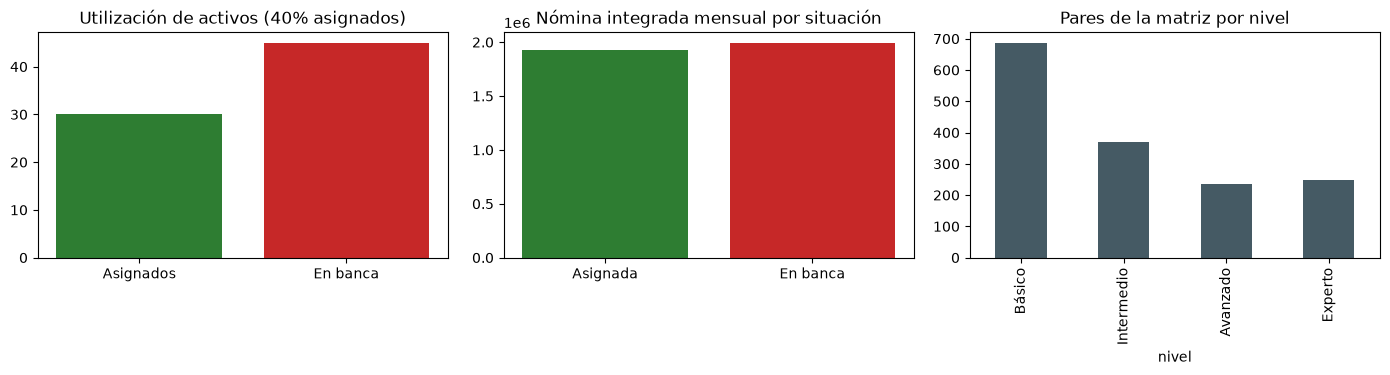

In [11]:
fig, ejes = plt.subplots(1, 3, figsize=(14, 4))

ejes[0].bar(['Asignados', 'En banca'], [len(con_asig), len(banca)], color=['#2e7d32', '#c62828'])
ejes[0].set_title(f'Utilización de activos ({utilizacion:.0f}% asignados)')

ejes[1].bar(['Asignada', 'En banca'], [nom_asig, nom_banca], color=['#2e7d32', '#c62828'])
ejes[1].set_title('Nómina integrada mensual por situación')

mat.nivel.value_counts().reindex(['Básico', 'Intermedio', 'Avanzado', 'Experto']).plot.bar(ax=ejes[2], color='#455a64')
ejes[2].set_title('Pares de la matriz por nivel')

plt.tight_layout()
plt.show()

In [12]:
# Cobertura de habilidades y activos, dos frentes que el resumen actual no muestra
print('Habilidades por tecnología')
print(hab.tecnologia.value_counts().to_string())
print()
print('Top de habilidades con más expertos')
expertos = mat[mat.nivel == 'Experto'].groupby(['tecnologia', 'habilidad']).uid_colaborador.nunique().sort_values(ascending=False)
print(expertos.head(10).to_string())
print()
print('Activos por marca normalizada')
print(act.assign(marca_norm=act.marca.str.strip().str.upper()).marca_norm.value_counts().to_string())
print()
print(f'Valor registrado del inventario: ${act.costo.sum():,.2f} con {(act.costo.fillna(0) == 0).sum()} equipos sin costo')
print(f'Equipos actualmente con colaboradores dados de baja: {len(abiertos_baja)} resguardos abiertos')

Habilidades por tecnología
tecnologia
Oracle eBS                  30
Plataformas Tecnológicas    20
Oracle Fusion Cloud         17
Otros                        2
Idiomas                      1
Certificaciones              1

Top de habilidades con más expertos
tecnologia                habilidad           
Plataformas Tecnológicas  PLSQL                   16
Oracle eBS                INV                     14
Plataformas Tecnológicas  REPORTS                 13
Certificaciones           CERTIFICADO ORACLE      12
Oracle eBS                Oracle EBS              12
                          PO                      10
Plataformas Tecnológicas  PUBLISHER               10
Oracle eBS                OM                       9
Plataformas Tecnológicas  FORMS                    8
                          FORMS PERSONALIZADOS     8

Activos por marca normalizada
marca_norm
DELL      62
HP        26
LENOVO    24
ACER       9
ASUS       2

Valor registrado del inventario: $567,915.55 con 70 eq

## 7. Preguntas de análisis detonadoras

Las preguntas que fortalecen el estudio y que deben poder responderse con datos son las siguientes. Quiénes están asignados y quiénes no a una fecha dada y cuánto tiempo llevan así. Quiénes terminan pronto una asignación y en qué proyecto y cliente. Qué porcentaje de la nómina está asignado y cuánto cuesta la gente que está sin proyecto. Cuál es el costo por experto en un proyecto por hora derivado de su salario mensual. Cuál es el margen por cliente y por proyecto al cruzar su ingreso con el costo de su gente asignada. Qué habilidades se tienen, en qué nivel y cuáles faltan para los proyectos que vienen. Qué colaboradores están en riesgo de salir por antigüedad, costo o tiempo sin asignación. Qué equipo sigue en poder de personas que ya salieron y cuánto vale el inventario real. Qué tan completo y confiable está el expediente de cada colaborador para poder confiar en los demás indicadores.

## 8. Métricas, indicadores y atributos adicionales

Las métricas que ya existen en las fuentes son los conteos de colaboradores por estatus, las asignaciones registradas, los clientes y proyectos, los componentes de sueldo por colaborador, los pares de habilidad por nivel y el costo registrado de los activos. Las métricas que deben agregarse son la utilización, el costo de banca, el costo por hora por experto, el costo mensual por proyecto, la rotación por periodo, el cumplimiento de expediente y la cobertura de habilidades por proyecto. Los indicadores necesarios son el porcentaje de utilización con su meta, el porcentaje y el monto de nómina asignada contra no asignada, las asignaciones por vencer en los siguientes treinta días, el margen por proyecto, la rotación mensual y anual, el porcentaje de expediente completo y el número de alertas abiertas por datos faltantes o inconsistentes. Los atributos adicionales que se requieren para responder todo lo anterior son la fecha de fin real y el porcentaje de dedicación en cada asignación, el código único de proyecto ligado a su ingreso y a su tarifa facturable, las horas facturables reales por colaborador, la fecha de evaluación y el evaluador en cada habilidad, el motivo de baja, el responsable y el centro de costos en cada departamento, y el registro de quién hizo cada cambio y cuándo.

## 9. Conclusión de la exploración

Las fuentes alcanzan para medir la utilización y el costo de la banca desde hoy, pues con los datos actuales solo el 40.0% de los colaboradores activos tiene una asignación registrada y el 50.9% de la nómina integrada mensual está en gente sin proyecto, pero no alcanzan todavía para saber quién termina pronto ni para calcular márgenes, porque faltan las fechas de fin, el porcentaje de dedicación y el ingreso por proyecto. Por eso la solución final que se propone en el documento de esta etapa es un análisis de brechas con un prototipo visual de un apartado de analítica dentro de la misma PWA, y no una modificación a la aplicación del socio.